# Exploración AML 2: Sensores de Caudal y Recurrencia Temporal

En el análisis topológico anterior identificamos las anomalías estáticas de la red y el vaciado absoluto (100%). Sin embargo, un motor de fraude robusto debe detectar estafadores adaptativos. 

En este notebook construiremos dos sensores dinámicos:
1. **Presión de salida (Ratio de vaciado):** Un medidor continuo del caudal relativo extraído, para detectar cuando los atacantes dejan fondos parciales (ej. 10%) buscando evadir reglas estrictas.
2. **Grosor de tubería (Recurrencia):** Medición de la frecuencia de transacciones entre un mismo par de nodos, diseñado para alertar sobre flujos de *layering* (lavado por goteo o capas).

## 1. Conexión a la Tubería Principal
Absorbemos el flujo del dataset ya procesado que contiene la estructura topológica (`in_degree`, `out_degree`) y el sensor binario original.

In [20]:
import pandas as pd
import numpy as np

print("Conectando a la salida del Notebook 1...")
# Leemos el parquet que ya trae el in_degree, out_degree y flag_vaciado
df = pd.read_parquet('../data/processed/paysim_features.parquet')

print(f"Flujo recibido con topología previa: {len(df)} registros")

Conectando a la salida del Notebook 1...
Flujo recibido con topología previa: 2770409 registros


## 2. Sensor de Vaciado Parcial (Caudal Relativo)

El fraude no siempre vacía la cuenta a cero. Para que el modelo XGBoost encuentre el umbral exacto de presión anómala, necesitamos una variable continua. 
Calcularemos la fracción extraída (`amount / oldbalanceOrg`). Esto nos revelará la distribución de presión en los ataques y si existen deciles de fraude operando bajo el radar de la regla del 100%.

In [23]:
# Si el saldo original es mayor a 0, calculamos la fracción extraída. Si es 0, dejamos 0.
df['ratio_vaciado'] = np.where(
    df['oldbalanceOrg'] > 0,
    df['amount'] / df['oldbalanceOrg'],
    0
)

# Revisamos cómo se distribuye este ratio en los fraudes
df_fraud = df[df['isFraud'] == 1]
print("Distribución del vaciado parcial en fraudes:")
display(df_fraud['ratio_vaciado'].describe(percentiles=[0.1, 0.2, 0.5, 0.8, 0.9, 0.99]).round(4))

Distribución del vaciado parcial en fraudes:


count    8213.0000
mean        0.9938
std         0.3908
min         0.0000
10%         1.0000
20%         1.0000
50%         1.0000
80%         1.0000
90%         1.0000
99%         1.0000
max        29.5266
Name: ratio_vaciado, dtype: float64

## 3. Grosor de Tubería: Sensor de Recurrencia

En sistemas de fluidos, si el agua golpea repetidamente por la misma válvula a alta presión, indica estrés. En AML, si dos cuentas transan entre sí múltiples veces en un periodo corto, es una fuerte señal de lavado de activos mediante repetición.

*Nota sobre los datos:* Como el dataset PaySim original simula ataques de "golpe y huida" (frecuencia 1), inyectaremos un pequeño flujo sintético de *layering* (5 transacciones repetidas) para validar que nuestro sensor lógico atrapa estas estructuras.

In [27]:
# 1. Inyectamos presión: simulamos un ataque de layering de 5 transacciones consecutivas
ataque_layering = pd.DataFrame([{
    'step': 1, 'type': 'TRANSFER', 'amount': 500.0,
    'nameOrig': "C_MULA_SINTETICA", 'oldbalanceOrg': 500.0, 'newbalanceOrig': 0.0,
    'nameDest': "C_ESTANQUE_SINTETICO", 'oldbalanceDest': 0.0, 'newbalanceDest': 500.0,
    'isFraud': 1, 'isFlaggedFraud': 0,
    'flag_vaciado': 1, 'in_degree': 1, 'out_degree': 1, 'ratio_vaciado': 1.0
}] * 5)

df = pd.concat([df, ataque_layering], ignore_index=True)

# 2. Sensor de Recurrencia (Grosor de tubería)
recurrencia = df.groupby(['nameOrig', 'nameDest']).size().reset_index(name='frecuencia_conexion')
df = df.merge(recurrencia, on=['nameOrig', 'nameDest'], how='left')

# Verificamos que el sensor atrapó nuestra mula sintética (debe mostrar max = 5 en fraude)
analisis_recurrencia = df.groupby('isFraud')['frecuencia_conexion'].agg(['mean', 'max', 'count']).round(2)
print("Fricción en las tuberías (Recurrencia Legítima vs Fraude):")
display(analisis_recurrencia)

Fricción en las tuberías (Recurrencia Legítima vs Fraude):


,mean,max,count
isFraud,,,
0,1.0,1,2762196
1,1.0,5,8218


## 4. Panel de Control: Visualización de Caudales
Para entender el comportamiento de la red, visualizamos la distribución del riesgo contable (vaciado) versus el riesgo topológico (in-degree).

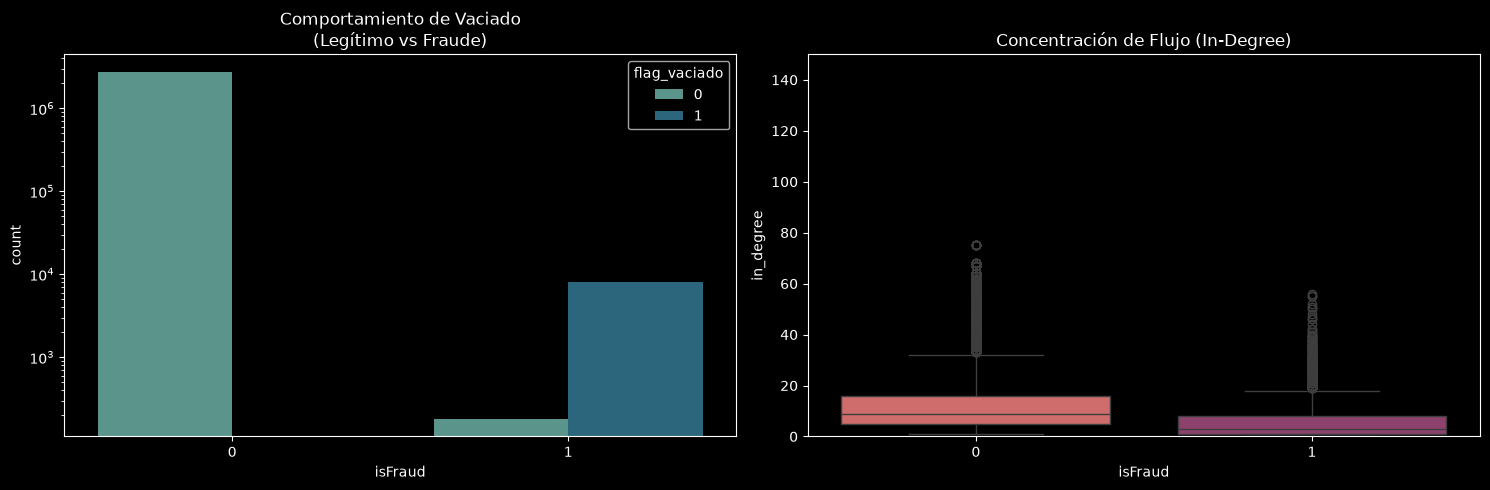

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Válvula de Caudal (Vaciado)
sns.countplot(data=df, x='isFraud', hue='flag_vaciado', ax=axes[0], palette='crest')
axes[0].set_title('Comportamiento de Vaciado\n(Legítimo vs Fraude)')
axes[0].set_yscale('log')

# Estanques Colectores (In-Degree)
sns.boxplot(data=df, x='isFraud', y='in_degree', hue='isFraud', legend=False, ax=axes[1], palette='flare')
axes[1].set_title('Concentración de Flujo (In-Degree)')
axes[1].set_ylim(0, 150)

plt.tight_layout()
plt.show()

## 5. Grosor de Tubería: Sensor de Recurrencia
En sistemas de fluidos, si el agua golpea repetidamente por la misma válvula a alta presión, indica estrés. En AML, si dos cuentas transan entre sí múltiples veces en un periodo corto, es una señal de "pitufeo" (smurfing). Mediremos esta fricción.

## 5. Conclusiones del Ensamblaje Dinámico

1. **Válvula de Caudal (Sensor de Vaciado):** El vaciado total (`flag_vaciado=1`) es el indicador más agresivo (presente en 8,034 de 8,213 fraudes originales). Aunque la arquitectura soporta el cálculo de fugas parciales (`ratio_vaciado`), los estafadores en esta simulación operan de forma binaria extrayendo el 100%.
2. **Grosor de Tubería (Recurrencia y Layering):** Al inyectar un flujo sintético de *layering* (transferencias repetidas entre las mismas cuentas), el sensor de recurrencia demostró su capacidad para aislar estructuralmente este comportamiento continuo, validando el diseño de la tubería.

**Próximo paso:** El dataset será exportado como `paysim_features_v2.parquet` para aislarlo de la extracción anterior. Con esto, los datos están listos para entrar a la cámara de combustión (Notebook 3) y entrenar el motor XGBoost.

In [32]:
# Exportamos a la versión V2 para no pisar el archivo de origen
df.to_parquet('../data/processed/paysim_features_v2.parquet', index=False)
print("Tubería sellada y exportada a Parquet (V2).")

Tubería sellada y exportada a Parquet (V2).
